# 02 伙伴链数分布

读取第二步生成的逐帧归一化分布 CSV，只负责作图。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path("..")
if not (ROOT / "results").is_dir():
    raise FileNotFoundError("请从本文件夹的 notebook/ 目录启动 Jupyter")
RESULTS = ROOT / "results"
OUTPUT_DIR = ROOT / "figures/02_distribution"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VARIANTS = ("A18_T260", "B01_T260", "B10_T260")
THRESHOLDS = (1, 5)
COLORS = {"A18_T260": "#777777", "B01_T260": "#326db3", "B10_T260": "#d16829"}


### 绘图函数

In [2]:
def plot_distributions(mean: pd.DataFrame, block: pd.DataFrame,
                       out_dir: Path) -> None:
    plt.rcParams.update({"font.size": 9, "axes.spines.top": False,
                         "axes.spines.right": False, "svg.fonttype": "none"})
    fig, axes = plt.subplots(1, 2, figsize=(9.1, 3.35), sharey=True,
                             constrained_layout=True)
    max_k = int(mean.loc[mean.mean_frame_fraction.gt(0), "partner_count"].max())
    for ax, threshold in zip(axes, THRESHOLDS):
        for variant in VARIANTS:
            d = mean[(mean.variant == variant) & (mean.threshold == threshold)]
            b = block[(block.variant == variant) & (block.threshold == threshold)]
            sd = (b.groupby("partner_count")["mean_block_fraction"].std()
                  .reindex(d.partner_count).fillna(0).to_numpy())
            k = d.partner_count.to_numpy()
            p = d.mean_frame_fraction.to_numpy()
            ax.plot(k, p, color=COLORS[variant], lw=2, marker="o", ms=2.2,
                    label=variant.replace("_T260", ""))
            ax.fill_between(k, np.maximum(0, p - sd), p + sd,
                            color=COLORS[variant], alpha=0.10, linewidth=0)
        ax.set(title=f"At least {threshold} residue contact{'s' if threshold > 1 else ''}",
               xlabel="Number of partner chains per dense chain", xlim=(-0.5, max_k + 0.5))
        ax.set_xticks(np.arange(0, max_k + 1, 2))
    axes[0].set_ylabel("Mean fraction of dense chains per frame")
    axes[1].legend(title="Variant", frameon=False)
    fig.suptitle("T260: partner-count distribution in the dense core", fontsize=11)
    for extension in ("png", "svg", "pdf"):
        fig.savefig(out_dir / f"partner_count_distribution_threshold1_5.{extension}",
                    dpi=250, bbox_inches="tight")
    plt.close(fig)


### 读取分布 CSV 并绘图

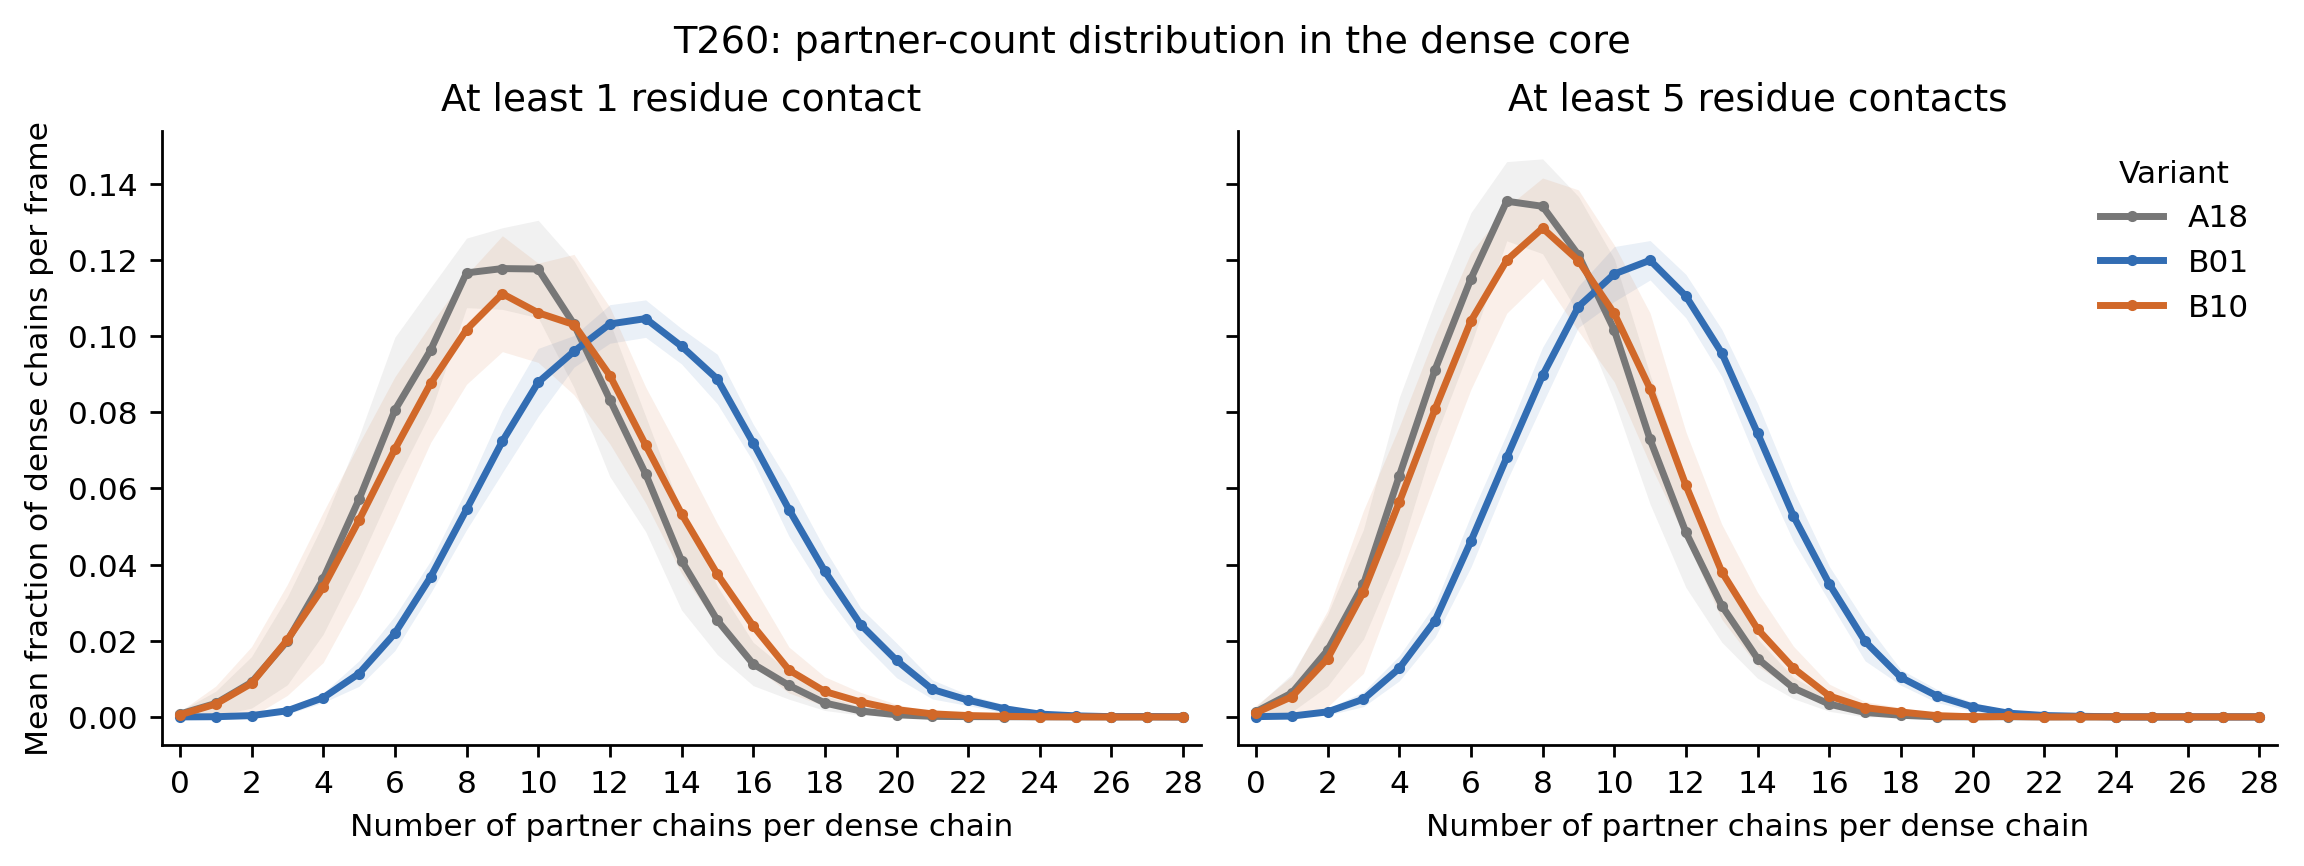

In [3]:
mean = pd.read_csv(RESULTS / "partner_count_distribution.csv")
block = pd.read_csv(RESULTS / "partner_count_distribution_by_block.csv")
plot_distributions(mean, block, OUTPUT_DIR)
display(Image(filename=str(OUTPUT_DIR / "partner_count_distribution_threshold1_5.png")))
